# 📊 Visualización de Datos con Matplotlib y Seaborn

En este cuaderno implementamos y comparamos **5 gráficos estadísticos fundamentales**, que son medianamente sencillos pero muy informativos:

1. **Gráfico de Líneas (Line Plot)**: Muestra tendencias o evoluciones temporales.
2. **Gráfico de Barras (Bar Plot)**: Compara cantidades o totales entre distintas categorías.
3. **Histograma (Histogram)**: Visualiza la distribución de frecuencias de una variable continua.
4. **Gráfico de Dispersión (Scatter Plot)**: Analiza la relación o correlación entre dos variables numéricas.
5. **Diagrama de Cajas (Box Plot)**: Representa la dispersión, mediana, cuartiles y valores atípicos entre grupos.

---
El cuaderno está dividido en tres secciones:
- **Paso 0:** Generación de un conjunto de datos sintético y reproducible.
- **Paso 1:** Implementación de los 5 gráficos con **Matplotlib**.
- **Paso 2:** Implementación de los mismos 5 gráficos con **Seaborn**.


In [1]:
# Importación de librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo y semilla aleatoria para reproducibilidad
np.random.seed(42)
print("Librerías importadas correctamente.")


Librerías importadas correctamente.


## 📁 Paso 0: Conjunto de Datos de Ejemplo

Generamos un dataset simulado de ventas de una tienda para el año 2024:
- `Mes`: Meses del año.
- `Categoria`: Tipo de producto (Electrónica, Ropa, Hogar, Libros, Deportes).
- `Ventas`: Monto en miles de euros.
- `Publicidad`: Gasto en publicidad en miles de euros.
- `Satisfaccion`: Puntuación del cliente (1 a 10).
- `Metodo_Pago`: Efectivo, Tarjeta, Transferencia.


In [2]:
# 1. Datos agregados mensuales para gráfico de líneas
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
ventas_mensuales = [18, 22, 25, 29, 35, 42, 48, 45, 38, 40, 52, 65]
df_mensual = pd.DataFrame({'Mes': meses, 'Ventas': ventas_mensuales})

# 2. Datos individuales para el resto de gráficos (200 transacciones)
n_muestras = 200
categorias = ['Electrónica', 'Ropa', 'Hogar', 'Libros', 'Deportes']
metodos_pago = ['Tarjeta', 'Efectivo', 'Transferencia']

df = pd.DataFrame({
    'Categoria': np.random.choice(categorias, size=n_muestras, p=[0.3, 0.25, 0.2, 0.15, 0.1]),
    'Publicidad': np.random.uniform(2, 20, size=n_muestras),
    'Metodo_Pago': np.random.choice(metodos_pago, size=n_muestras, p=[0.6, 0.25, 0.15]),
    'Satisfaccion': np.clip(np.random.normal(loc=7.5, scale=1.3, size=n_muestras), 1, 10)
})

# Las ventas están correlacionadas positivamente con la inversión en publicidad y varían según la categoría
factor_cat = {'Electrónica': 15, 'Ropa': 10, 'Hogar': 8, 'Libros': 5, 'Deportes': 9}
df['Ventas'] = (df['Publicidad'] * 1.8 + df['Categoria'].map(factor_cat) + np.random.normal(0, 4, size=n_muestras)).round(2)
df['Satisfaccion'] = df['Satisfaccion'].round(1)

df.head()


,Categoria,Publicidad,Metodo_Pago,Satisfaccion,Ventas
0,Ropa,13.556570,Tarjeta,6.8,44.70
1,Deportes,3.514519,Transferencia,6.5,15.56
2,Hogar,4.909317,Tarjeta,7.4,16.89
3,Hogar,18.173975,Efectivo,6.2,40.62
4,Electrónica,12.915723,Tarjeta,6.8,39.04


---
# 🟦 PARTE 1: Los 5 Gráficos con Matplotlib

Matplotlib es la biblioteca base de visualización en Python. Requiere un control más explícito de cada elemento visual (ejes, colores, etiquetas).


### 1. Gráfico de Líneas con Matplotlib
Útil para observar tendencias temporales (evolución de ventas mensuales).


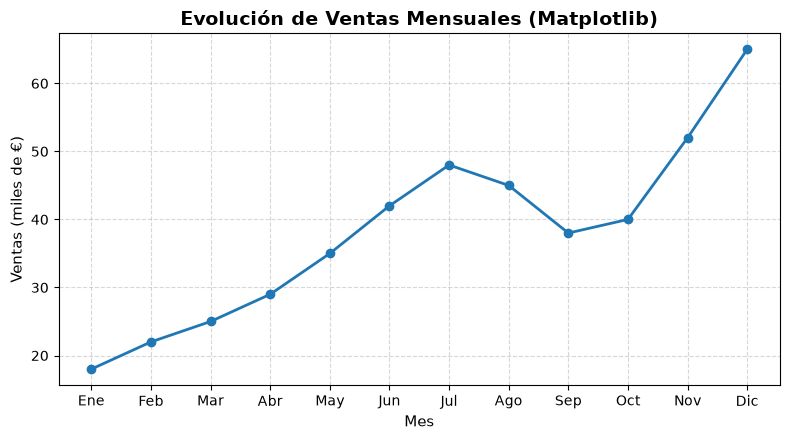

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(df_mensual['Mes'], df_mensual['Ventas'], marker='o', color='#1f77b4', linewidth=2, markersize=6)
ax.set_title('Evolución de Ventas Mensuales (Matplotlib)', fontsize=14, fontweight='bold')
ax.set_xlabel('Mes', fontsize=11)
ax.set_ylabel('Ventas (miles de €)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 2. Gráfico de Barras con Matplotlib
Útil para comparar magnitudes totales o medias entre categorías.


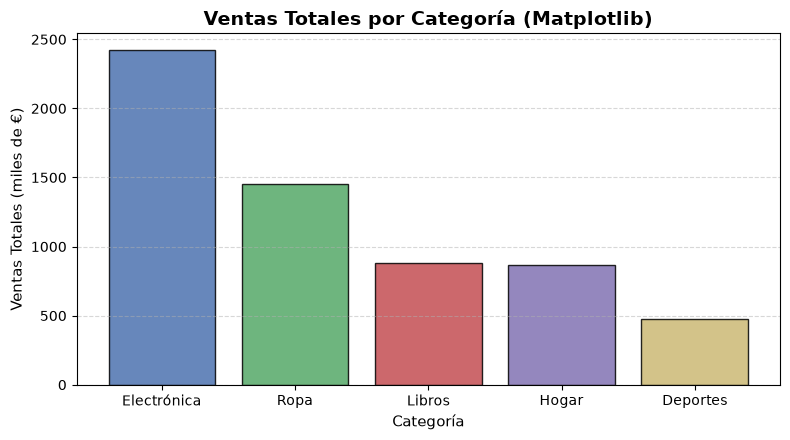

In [4]:
# Calculamos ventas totales por categoría
ventas_por_cat = df.groupby('Categoria')['Ventas'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))

colores = ['#4c72b0', '#55a868', '#c44e52', '#8172b3', '#ccb974']
ax.bar(ventas_por_cat.index, ventas_por_cat.values, color=colores, edgecolor='black', alpha=0.85)

ax.set_title('Ventas Totales por Categoría (Matplotlib)', fontsize=14, fontweight='bold')
ax.set_xlabel('Categoría', fontsize=11)
ax.set_ylabel('Ventas Totales (miles de €)', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 3. Histograma con Matplotlib
Útil para analizar la distribución y dispersión de una variable continua (Nivel de Satisfacción).


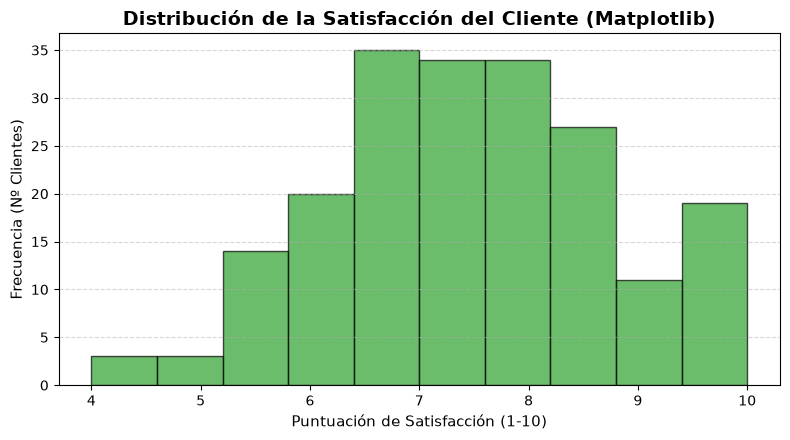

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(df['Satisfaccion'], bins=10, color='#2ca02c', edgecolor='black', alpha=0.7)

ax.set_title('Distribución de la Satisfacción del Cliente (Matplotlib)', fontsize=14, fontweight='bold')
ax.set_xlabel('Puntuación de Satisfacción (1-10)', fontsize=11)
ax.set_ylabel('Frecuencia (Nº Clientes)', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 4. Gráfico de Dispersión (Scatter Plot) con Matplotlib
Útil para evaluar la relación entre Inversión en Publicidad y Ventas obtenidas.


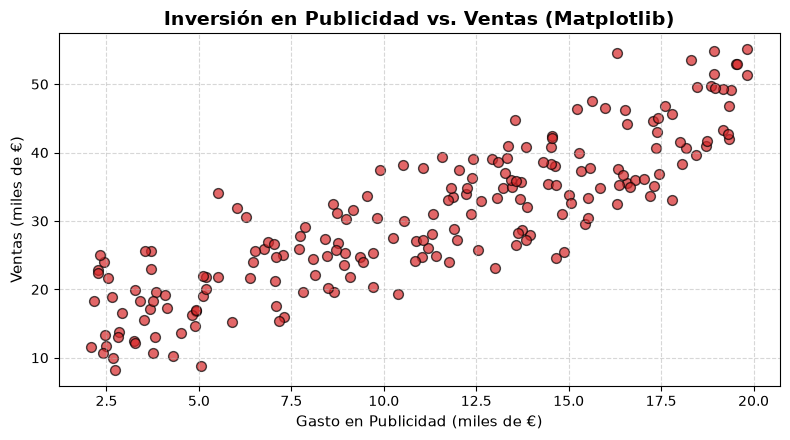

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.scatter(df['Publicidad'], df['Ventas'], color='#d62728', alpha=0.7, edgecolors='black', s=50)

ax.set_title('Inversión en Publicidad vs. Ventas (Matplotlib)', fontsize=14, fontweight='bold')
ax.set_xlabel('Gasto en Publicidad (miles de €)', fontsize=11)
ax.set_ylabel('Ventas (miles de €)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 5. Diagrama de Cajas (Box Plot) con Matplotlib
Útil para comparar medianas, cuartiles y valores atípicos de las ventas según el método de pago.


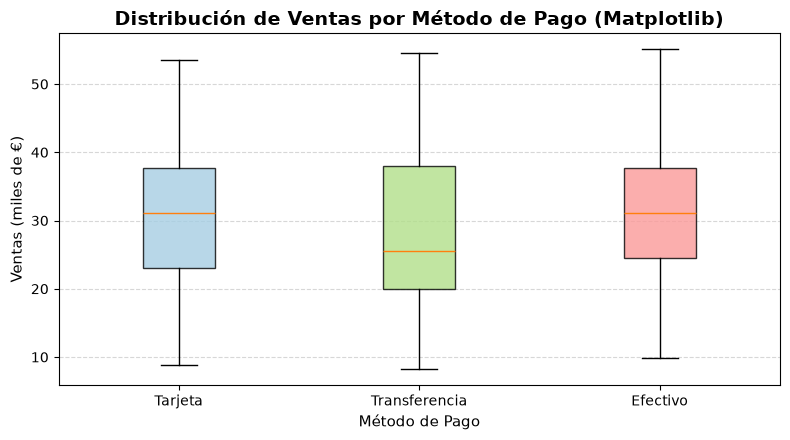

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Agrupamos datos para cada método de pago
metodos = df['Metodo_Pago'].unique()
datos_boxplot = [df[df['Metodo_Pago'] == m]['Ventas'].values for m in metodos]

box = ax.boxplot(datos_boxplot, tick_labels=metodos, patch_artist=True)

# Personalizamos los colores de las cajas
colores_box = ['#a6cee3', '#b2df8a', '#fb9a99']
for patch, color in zip(box['boxes'], colores_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax.set_title('Distribución de Ventas por Método de Pago (Matplotlib)', fontsize=14, fontweight='bold')
ax.set_xlabel('Método de Pago', fontsize=11)
ax.set_ylabel('Ventas (miles de €)', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
# 🟧 PARTE 2: Los Mismos 5 Gráficos con Seaborn

Seaborn es una biblioteca de visualización basada en Matplotlib orientada a DataFrames de pandas. Proporciona una sintaxis más concisa y temas visuales estilizados por defecto.


### 1. Gráfico de Líneas con Seaborn
Mismo gráfico de evolución mensual, usando `sns.lineplot()`.


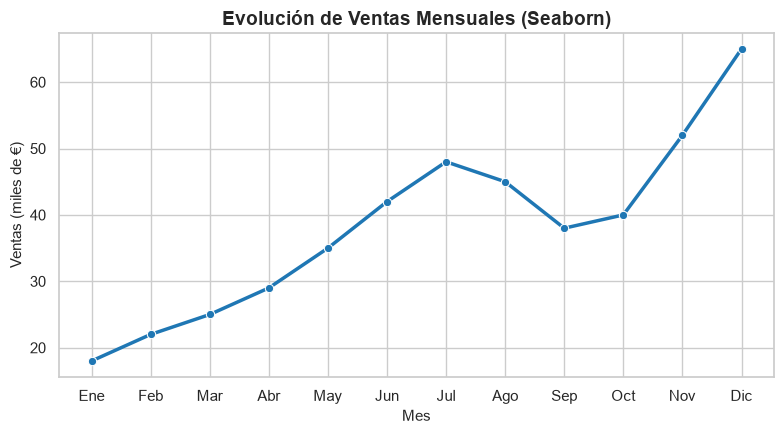

In [8]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.lineplot(data=df_mensual, x='Mes', y='Ventas', marker='o', ax=ax, color='#1f77b4', linewidth=2.5)

ax.set_title('Evolución de Ventas Mensuales (Seaborn)', fontsize=14, fontweight='bold')
ax.set_xlabel('Mes', fontsize=11)
ax.set_ylabel('Ventas (miles de €)', fontsize=11)

plt.tight_layout()
plt.show()


### 2. Gráfico de Barras con Seaborn
Mismo gráfico de ventas por categoría, usando `sns.barplot()`.


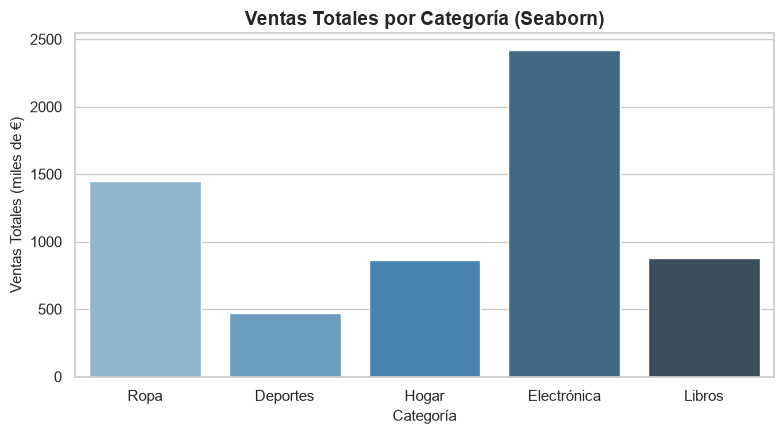

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(
    data=df, 
    x='Categoria', 
    y='Ventas', 
    estimator=np.sum, 
    errorbar=None, 
    palette='Blues_d', 
    hue='Categoria', 
    legend=False,
    ax=ax
)

ax.set_title('Ventas Totales por Categoría (Seaborn)', fontsize=14, fontweight='bold')
ax.set_xlabel('Categoría', fontsize=11)
ax.set_ylabel('Ventas Totales (miles de €)', fontsize=11)

plt.tight_layout()
plt.show()


### 3. Histograma con Seaborn
Misma distribución de satisfacción, usando `sns.histplot()` con curva de densidad (KDE).


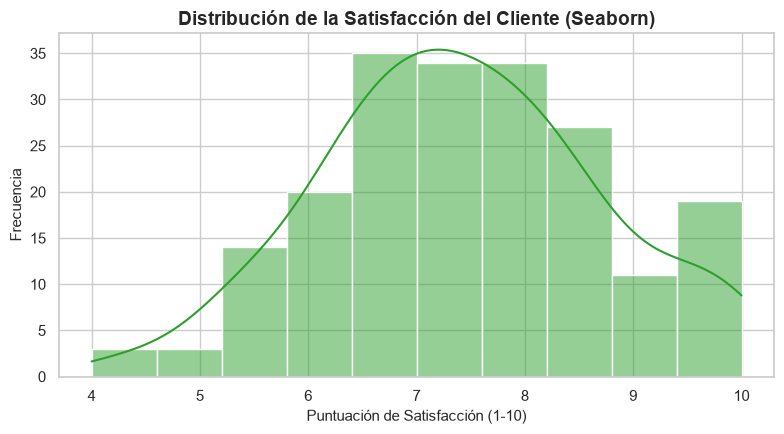

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.histplot(data=df, x='Satisfaccion', bins=10, kde=True, color='#2ca02c', ax=ax)

ax.set_title('Distribución de la Satisfacción del Cliente (Seaborn)', fontsize=14, fontweight='bold')
ax.set_xlabel('Puntuación de Satisfacción (1-10)', fontsize=11)
ax.set_ylabel('Frecuencia', fontsize=11)

plt.tight_layout()
plt.show()


### 4. Gráfico de Dispersión (Scatter Plot) con Seaborn
Misma relación Publicidad vs. Ventas, usando `sns.scatterplot()` y diferenciando por categoría con color.


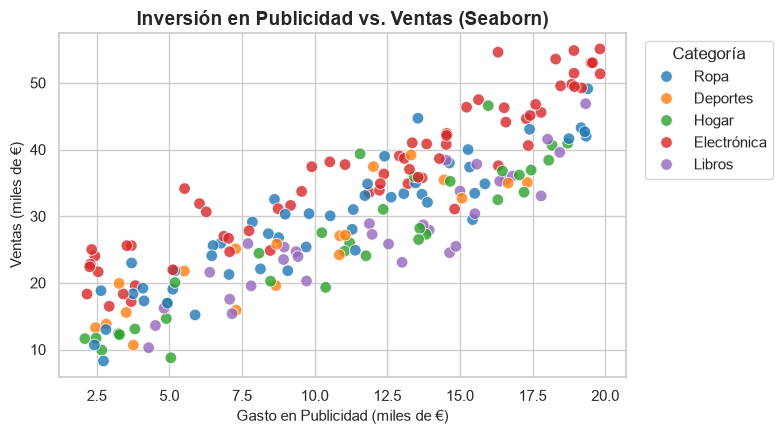

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.scatterplot(
    data=df, 
    x='Publicidad', 
    y='Ventas', 
    hue='Categoria', 
    palette='tab10', 
    s=70, 
    alpha=0.8, 
    ax=ax
)

ax.set_title('Inversión en Publicidad vs. Ventas (Seaborn)', fontsize=14, fontweight='bold')
ax.set_xlabel('Gasto en Publicidad (miles de €)', fontsize=11)
ax.set_ylabel('Ventas (miles de €)', fontsize=11)
ax.legend(title='Categoría', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


### 5. Diagrama de Cajas (Box Plot) con Seaborn
Mismo diagrama de dispersión de ventas por método de pago, usando `sns.boxplot()`.


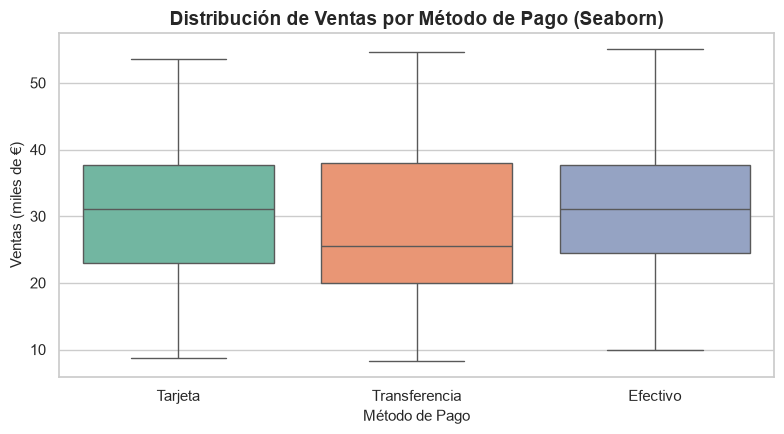

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.boxplot(
    data=df, 
    x='Metodo_Pago', 
    y='Ventas', 
    hue='Metodo_Pago',
    palette='Set2', 
    legend=False,
    ax=ax
)

ax.set_title('Distribución de Ventas por Método de Pago (Seaborn)', fontsize=14, fontweight='bold')
ax.set_xlabel('Método de Pago', fontsize=11)
ax.set_ylabel('Ventas (miles de €)', fontsize=11)

plt.tight_layout()
plt.show()


---
## 🎯 Resumen y Comparativa

| Gráfico | Función en Matplotlib | Función en Seaborn | Aplicación Típica |
| :--- | :--- | :--- | :--- |
| **1. Líneas** | `ax.plot()` | `sns.lineplot()` | Series temporales, tendencias |
| **2. Barras** | `ax.bar()` | `sns.barplot()` | Comparación entre categorías discretas |
| **3. Histograma** | `ax.hist()` | `sns.histplot()` | Distribución y frecuencias de una variable continua |
| **4. Dispersión** | `ax.scatter()` | `sns.scatterplot()` | Relación/correlación entre dos variables numéricas |
| **5. Cajas (Boxplot)**| `ax.boxplot()` | `sns.boxplot()` | Mediana, cuartiles y valores atípicos entre grupos |

- **Matplotlib** ofrece control total de cada componente geométrico a nivel de API.
- **Seaborn** simplifica la creación de gráficos estadísticos complejos trabajando directamente con columnas de DataFrames y aplicando paletas de color armoniosas.
